# Cервис проката самокатов GoFast

- Автор: Наталья Пронько
- Дата: 10.08.2026

## Цель и задачи

**Цель:** Провести анализ данных сервиса проката самокатов GoFast для выявления закономерностей в поведении пользователей и оценки потенциальной выгоды от распространения платной подписки.

**Задачи:**
1. Загрузить данные и познакомиться с их содержанием.
2. Провести предобработку данных.
3. Провести исследовательский анализ данных.
4. Объединить данные о пользователях, поездках и подписках.
5. Подсчитать выручку по месяцам для каждой категории пользователей.
6. Проверить гипотезы о различиях в поведении подписчиков и пользователей без подписки.
7. Смоделировать распределение длительности поездок и рассчитать критические значения.

## Данные

Для анализа поступили данные от сервиса проката самокатов GoFast за один год. Информация состоит из трех датасетов:
- `users_go.csv` — информация о пользователях сервиса;
- `rides_go.csv` — информация о поездках пользователей;
- `subscriptions_go.csv` — информация о стоимости услуг в подписках.

### Описание датасета `users_go.csv`

- `user_id` — уникальный идентификатор пользователя;
- `name` — имя пользователя;
- `age` — возраст;
- `city` — город;
- `subscription_type` — тип подписки: free, ultra.

### Описание датасета `rides_go.csv`

- `user_id` — уникальный идентификатор пользователя;
- `distance` — расстояние в метрах, которое пользователь проехал в текущей сессии;
- `duration` — продолжительность сессии в минутах, то есть время с того момента, как пользователь нажал кнопку «Начать поездку», до того, как он нажал кнопку «Завершить поездку»;
- `date` — дата совершения поездки.

### Описание датасета `subscriptions_go.csv`

- `subscription_type` — тип подписки;
- `minute_price` — стоимость одной минуты поездки по этой подписке;
- `start_ride_price` — стоимость начала поездки;
- `subscription_fee` — стоимость ежемесячного платежа.

## План работы

### Шаг 1. Загрузка данных
1.1 Считать CSV-файлы с данными с помощью библиотеки pandas и сохранить их в датафреймы.

1.2 Вывести первые строки каждого набора данных. Изучить общую информацию о каждом датафрейме.

### Шаг 2. Предобработка данных
2.1 Привести столбец `date` в датафрейме `df_rides_go` к типу даты pandas.

2.2 Создать новый столбец с номером месяца на основе столбца `date`.

2.3 Проверить наличие пропущенных значений и дубликатов в датафреймах. Обработать их, если такие значения присутствуют.

### Шаг 3. Исследовательский анализ данных
Описать и визуализировать общую информацию о пользователях и поездках:
- частота встречаемости городов;
- соотношение пользователей с подпиской и без подписки;
- возраст пользователей;
- расстояние, которое пользователь преодолел за одну поездку;
- продолжительность поездок.

### Шаг 4. Объединение данных
4.1 Объединить данные о пользователях, поездках и подписках в один датафрейм с помощью метода `merge()`.

4.2 Создать еще два датафрейма из объединенного датафрейма:
- с данными о пользователях без подписки;
- с данными о пользователях с подпиской.

4.3 Визуализировать информацию о расстоянии и времени поездок для пользователей обеих категорий.

### Шаг 5. Подсчет выручки
5.1 Объединенные данные сгруппировать по столбцам с идентификатором пользователя, именем, типом подписки и номером месяца. Затем создать датафрейм с агрегированными данными о поездках: суммарное расстояние, количество поездок и суммарное время для каждого пользователя за каждый месяц.

5.2 Добавить в датафрейм столбец с выручкой по месяцам, которую принес каждый пользователь. Для этого обратиться к информации об условиях оплаты для подписчиков и тех, у кого нет подписки.

### Шаг 6. Проверка гипотез
6.1 Проверить гипотезу: тратят ли пользователи с подпиской больше времени на поездки? Использовать данные о продолжительности каждой сессии — отдельно для подписчиков и тех, у кого нет подписки.

6.2 Проверить гипотезу: можно ли сказать, что расстояние, которое проезжают пользователи с подпиской за одну поездку, не превышает 3130 метров?

6.3 Проверить гипотезу: будет ли помесячная выручка от пользователей с подпиской по месяцам выше, чем выручка от пользователей без подписки?

### Шаг 7. Распределения
7.1 Рассчитать среднюю длительность поездки и стандартное отклонение длительности на основе выборки.

7.2 Смоделировать длительность поездки с помощью нормального распределения, используя выборочное среднее и стандартное отклонение. Рассчитать вероятность поездки более 30 минут с помощью CDF.

7.3 Определить процент пользователей, совершающих поездки в интервале от 20 до 30 минут.

7.4 Рассчитать критическую дистанцию (90-й процентиль), превышение которой будет сопровождаться дополнительной платой.

## Ожидаемый результат

Обоснованные выводы о целесообразности расширения платной подписки, рекомендации по проведению промоакций и установлению тарифной политики на основе статистической проверки гипотез.

## 1. Загрузка данных и знакомство с ними
Начнем с загрузки библиотек и датасетов `users_go.csv`, `rides_go.csv` и `subscriptions_go.csv`. Будем использовать `pandas` и библиотеки  `matplotlib` для визуализации данных и  `scipy.stats` для проверки гипотез. Данные датасетов сохраним в трех переменных: `df_users_go`, `df_rides_go` и `df_subscriptions_go`.

In [78]:
# Импортируем библиотеки
import pandas as pd

import matplotlib.pyplot as plt

import scipy.stats as st

import warnings
warnings.filterwarnings('ignore')

In [43]:
# Выгружаем данные в переменные df_users_go, df_rides_go, df_subscriptions_go 
df_users_go = pd.read_csv('users_go.csv')
df_rides_go = pd.read_csv('rides_go.csv')
df_subscriptions_go = pd.read_csv('subscriptions_go.csv')

Познакомимся с данными датасетов, выведем информацию о датафреймах методом `info()`, а первые строки методом `head()`:

In [44]:
# Знакомимся с данными: выводим info() и head() для каждого датафрейма

for name, df in [('df_users_go', df_users_go),
                 ('df_rides_go', df_rides_go),
                 ('df_subscriptions_go', df_subscriptions_go)]:
    print('=' * 60)
    print(f'Датафрейм: {name}')
    print('=' * 60)
    print('\n--- info() ---')
    df.info()
    print('\n--- head() ---')
    display(df.head())
    print('\n')

Датафрейм: df_users_go

--- info() ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1565 entries, 0 to 1564
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   user_id            1565 non-null   int64 
 1   name               1565 non-null   object
 2   age                1565 non-null   int64 
 3   city               1565 non-null   object
 4   subscription_type  1565 non-null   object
dtypes: int64(2), object(3)
memory usage: 61.3+ KB

--- head() ---


,user_id,name,age,city,subscription_type
0,1,Кира,22,Тюмень,ultra
1,2,Станислав,31,Омск,ultra
2,3,Алексей,20,Москва,ultra
3,4,Константин,26,Ростов-на-Дону,ultra
4,5,Адель,28,Омск,ultra




Датафрейм: df_rides_go

--- info() ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18068 entries, 0 to 18067
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   user_id   18068 non-null  int64  
 1   distance  18068 non-null  float64
 2   duration  18068 non-null  float64
 3   date      18068 non-null  object 
dtypes: float64(2), int64(1), object(1)
memory usage: 564.8+ KB

--- head() ---


,user_id,distance,duration,date
0,1,4409.919140,25.599769,2021-01-01
1,1,2617.592153,15.816871,2021-01-18
2,1,754.159807,6.232113,2021-04-20
3,1,2694.783254,18.511000,2021-08-11
4,1,4028.687306,26.265803,2021-08-28




Датафрейм: df_subscriptions_go

--- info() ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   subscription_type  2 non-null      object
 1   minute_price       2 non-null      int64 
 2   start_ride_price   2 non-null      int64 
 3   subscription_fee   2 non-null      int64 
dtypes: int64(3), object(1)
memory usage: 192.0+ bytes

--- head() ---


,subscription_type,minute_price,start_ride_price,subscription_fee
0,free,8,50,0
1,ultra,6,0,199


## Вывод по общей информации о данных

Все три датафрейма успешно загружены, пропущенных значений нет, объём данных соответствует ожиданиям.

- **`df_users_go`** — 1565 записей, 5 столбцов. Присутствуют количественные признаки (`user_id`, `age`) и категориальные (`name`, `city`, `subscription_type`). Пропусков нет.
- **`df_rides_go`** — 18 068 записей, 4 столбца. Столбец `date` имеет тип `object`, поэтому на этапе предобработки его необходимо привести к `datetime`. Пропусков нет.
- **`df_subscriptions_go`** — справочная таблица с 2 записями (типы подписок `free` и `ultra`) и 4 столбцами с условиями оплаты. Пропусков нет.

**Что важно учесть дальше:**
- Преобразовать `date` в `df_rides_go` к типу `datetime` и извлечь номер месяца.
- Дополнительно проверить дубликаты в датафреймах .
- Объединить данные о пользователях, поездках и подписках через `merge()` по ключам `user_id` и `subscription_type`.

## 2. Предобработка данных

В датафрейме `df_rides_go` еще раз проверим тип данных атрибутом `dtypes`

In [45]:
df_rides_go.dtypes

user_id       int64
distance    float64
duration    float64
date         object
dtype: object

Приведем столбец date в датафрейме `df_rides_go` к типу даты pandas, используя метод `pd.to_datetime()`

In [46]:
df_rides_go['date'] = pd.to_datetime(df_rides_go['date'])

На основе столбца `date` создадим новый столбец `month`, содержащий номер месяца. Это нужно для последующей группировки данных и анализа сезонных трендов.

In [47]:
df_rides_go['month'] = df_rides_go['date'].dt.month

В датафрейме пользователей `df_users_go` определим количество дубликатов

In [48]:
df_users_go.duplicated().sum()

31

In [49]:
df_users_go[df_users_go.duplicated(keep=False)].sort_values(by='user_id')

,user_id,name,age,city,subscription_type
15,16,Амалия,27,Краснодар,ultra
1535,16,Амалия,27,Краснодар,ultra
42,43,Стефания,22,Омск,ultra
1539,43,Стефания,22,Омск,ultra
1563,47,Юрий,28,Тюмень,ultra
...,...,...,...,...,...
1554,1198,Демид,29,Ростов-на-Дону,free
1558,1237,Евгения,23,Тюмень,free
1236,1237,Евгения,23,Тюмень,free
1544,1245,Регина,27,Пятигорск,free


In [50]:
df_users_go.shape[0]

1565

Данные дубликаты можем смело удалять

In [51]:
df_users_go = df_users_go.drop_duplicates()

In [52]:
df_users_go.shape[0]

1534

31 дубликат удалили

В датафрейме поездок df_rides_go округлим время поездки duration до целого числа стандартным методом round(). Затем приведем эту колонку к целочисленному типу int. Это поможет нам позже правильно рассчитать прибыль, так как плата взимается только за целое число минут.

In [53]:
df_rides_go['duration'].dtypes

dtype('float64')

In [54]:
df_rides_go['duration'] = df_rides_go['duration'].round().astype(int)

In [55]:
df_rides_go['duration'].dtypes

dtype('int64')


В ходе предобработки данные были приведены к корректным типам, устранены дубликаты и подготовлены новые признаки для дальнейшего анализа.

- **Типы данных в `df_rides_go`:** столбец `date` имел тип `object`, поэтому был преобразован в `datetime` с помощью `pd.to_datetime()` — это позволяет работать с датами как с временными объектами и извлекать из них компоненты.
- **Новый признак `month`:** на основе столбца `date` создан столбец с номером месяца (`date.dt.month`) — он понадобится для группировки данных по месяцам и анализа сезонных трендов.
- **Дубликаты в `df_users_go`:** обнаружено **31 полных дубликатов** (полностью совпадающие строки, включая `user_id`). После удаления методом `drop_duplicates()` количество записей уменьшилось с **1565 до 1534**.
- **Приведение `duration` к целому типу:** продолжительность поездок изначально хранилась в `float64`. Так как оплата взимается за целое число минут, значения были округлены методом `round()` и приведены к типу `int64` через `astype(int)`.

**Итог:** данные готовы к дальнейшему исследовательскому анализу и объединению таблиц. Все типы соответствуют своему содержимому, дубликаты удалены, необходимые для группировок признаки созданы.

## 3. Исследовательский анализ данных (EDA)

Пользуясь данными из датафрейма `df_users_go`, изучим количество пользователей в каждом из городов

In [56]:
users_by_city_count = df_users_go['city'].value_counts()
print(users_by_city_count)

city
Пятигорск         219
Екатеринбург      204
Ростов-на-Дону    198
Краснодар         193
Сочи              189
Омск              183
Тюмень            180
Москва            168
Name: count, dtype: int64


Визуализируем результат в процентном соотношении

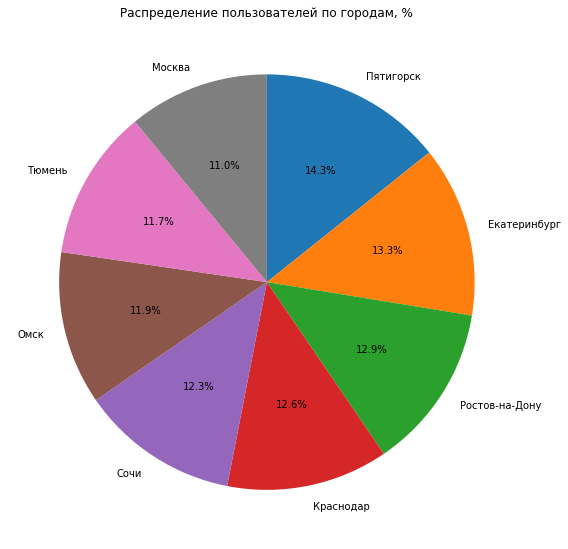

In [91]:
# Считаем доли в процентах
users_by_city_pct = df_users_go['city'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(
    users_by_city_pct,
    labels=users_by_city_pct.index,
    autopct='%1.1f%%',
    startangle=90,
    counterclock=False
)
ax.set_title('Распределение пользователей по городам, %')
plt.tight_layout()
plt.show()

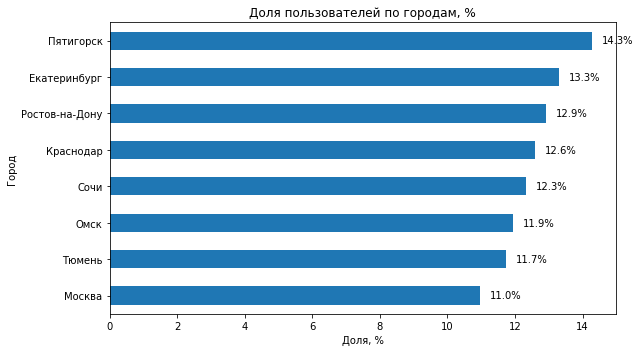

In [92]:
fig, ax = plt.subplots(figsize=(9, 5))
users_by_city_pct.sort_values().plot(kind='barh', ax=ax)
ax.set_title('Доля пользователей по городам, %')
ax.set_xlabel('Доля, %')
ax.set_ylabel('Город')

# Подписываем проценты на каждом столбце
for i, v in enumerate(users_by_city_pct.sort_values()):
    ax.text(v + 0.3, i, f'{v:.1f}%', va='center')

plt.tight_layout()
plt.show()

### Распределение пользователей по городам

- Всего в данных представлено **8 городов**, и пользователи распределены по ним **практически равномерно**.
- Лидер по числу пользователей — **Пятигорск** (219 человек, **14.3%**), на последнем месте — **Москва** (168 человек, **11.0%**).
- Разрыв между городами-лидерами минимален: доли всех городов лежат в узком диапазоне **от 11.0% до 14.3%**.
- Такой равномерный разброс говорит об отсутствии ярко выраженной географической концентрации — сервис одинаково востребован во всех представленных городах.

- География пользователей сбалансирована, что позволяет анализировать данные без сильного перекоса в сторону одного города.

Проверим количеством пользователей для каждого типа подписки

In [57]:
subscription_type_count = df_users_go['subscription_type'].value_counts()
print(subscription_type_count)

subscription_type
free     835
ultra    699
Name: count, dtype: int64


Визуализируем данные в процентном соотношении

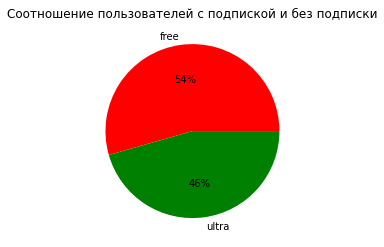

In [60]:
subscription_type_count.plot(
    kind= 'pie',
    title='Соотношение пользователей с подпиской и без подписки',
    autopct= '%.0f%%',
    ylabel='' ,
    colors=['red', 'green']
)

plt.show()

### Соотношение пользователей по типу подписки

- Пользователей **без подписки (`free`)** — **835 человек (54%)**.
- Пользователей **с подпиской (`ultra`)** — **699 человек (46%)**.
- То есть **более половины** пользователей сервиса не имеют платной подписки.

- Доля подписчиков (46%) достаточно высока, однако преобладание «бесплатных» пользователей подтверждает актуальность задачи бизнеса — **увеличить количество пользователей с подпиской**, что и будет проверяться в следующих шагах через гипотезы и расчёт выручки.

Перейдем к анализу возраста пользователей

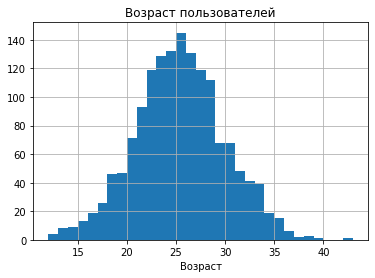

In [61]:
# Определим количество бинов n_bins как разницу между максимальным и минимальным значениями в столбце age
n_bins = df_users_go['age'].max() - df_users_go['age'].min()

# Используем метод hist() для столбца df_users_go['age']
df_users_go['age'].hist(bins=n_bins)

plt.title('Возраст пользователей')
plt.xlabel('Возраст')
plt.show()

- Распределение имеет **форму, близкую к нормальному**, с выраженным **одним пиком** в районе **25–26 лет**.
- Основная масса пользователей сосредоточена в диапазоне **20–33 лет** — это ядро целевой аудитории сервиса.
- Левый «хвост» распределения (подростки и молодёжь 12–19 лет) выражен слабо: таких пользователей немного.
- Правый «хвост» (35+ лет) тоже короткий — людей старше 35 заметно меньше, а после 40 лет они встречаются единично.
- Минимальный возраст пользователей — около **12 лет**, максимальный — примерно **42 года**.

**Интерпретация:**

- Аудитория сервиса — это преимущественно **молодые люди студенческого и раннего рабочего возраста (20–30 лет)**. Именно на них логично ориентировать маркетинговые кампании, промоакции и предложение подписки.
- Поскольку распределение близко к нормальному и унимодально, аномалий и выбросов в данных о возрасте практически нет — это удобно для дальнейших статистических проверок гипотез.
- Пользователи старшего возраста (35+) составляют небольшую долю — на них можно обратить внимание как на потенциально «недоиспользованный» сегмент, но приоритетом он не является.

Рассчитаем долю несовершеннолетних (возрастом менее 18 лет) пользователей самокатов.

In [62]:
users_under_18_ratio = round((df_users_go['age'] < 18).sum() / df_users_go.shape[0] * 100)
print(f'Доля несовершеннолетних пользователей самокатов составляет {users_under_18_ratio}%.')

Доля несовершеннолетних пользователей самокатов составляет 5%.


- Это **небольшая, но значимая доля** — примерно каждый двадцатый пользователь самокатов является несовершеннолетним.
- С точки зрения бизнеса это важный факт: **несовершеннолетние — особая категория пользователей**, для которой действуют дополнительные правовые и этические ограничения (правила сервиса, вопросы безопасности, согласие родителей, возможные региональные запреты на использование самокатов лицами младше 18 лет).
- В контексте задачи о распространении платной подписки **эта группа вряд ли является целевой аудиторией**: у несовершеннолетних обычно нет собственной платёжеспособности, а решения о платных подписках чаще принимают их родители.
- При этом 5% — не настолько большая доля, чтобы искажать общие выводы по возрастному распределению или результатам проверки гипотез. Тем не менее, при необходимости эту группу можно **исключить из анализа платёжеспособной аудитории** или рассматривать отдельно.
- Также это сигнал для бизнеса: возможно, стоит **ужесточить возрастную верификацию** при регистрации, чтобы снизить риски, связанные с использованием самокатов несовершеннолетними.

***

Изучим длительность поездок, так как это важная метрика в работе сервиса проката самокатов. Если средняя длительность поездок будет слишком высокой, самокаты будут быстрее выходить из строя. Если слишком низкой, значит, клиентам что-то не нравится в сервисе.

In [66]:
# Рассчитаем среднее значение и стандартное отклонение длительности поездки 
duration_mean = round(df_rides_go['duration'].mean())
duration_std = round(df_rides_go['duration'].std())

# Рассчитаем 25-й и 75-й процентили длительности поездки
duration_pct25 = round(df_rides_go['duration'].quantile(0.25))
duration_pct75 = round(df_rides_go['duration'].quantile(0.75))

print(f'Средняя длительность поездки {duration_mean} минут со стандартным отклонением {duration_std}. Основная часть поездок занимает от {duration_pct25} до {duration_pct75} минут.')

Средняя длительность поездки 18 минут со стандартным отклонением 6. Основная часть поездок занимает от 14 до 22 минут.


- Средняя поездка длится **около 18 минут** — это типичная короткая поездка «на последней миле»: добраться от дома до метро, от офиса до кафе, покататься в парке.
- Стандартное отклонение **всего 6 минут** при среднем 18 — разброс небольшой относительно среднего (коэффициент вариации ≈ 33%). Это говорит о том, что длительность поездок **достаточно стабильна**, без сильного разлёта значений.
- Диапазон **14–22 минуты** покрывает половину всех поездок — это удобный ориентир для продуктовых решений: например, для оценки тарифов, длительности промо-акций или расчёта времени аренды.
- **Важно для дальнейших шагов:** среднее (18 минут) заметно меньше порога **30 минут**, который фигурирует в задаче о скидках для длительных поездок. Это заранее подсказывает, что доля поездок дольше 30 минут будет **небольшой** — что подтвердится при моделировании нормального распределения в шаге 7.
- Также эти параметры (среднее и стандартное отклонение) будут использованы для построения **нормального распределения** длительности поездок в шаге 7.

## 4. Объединение данных

Объединим датафреймы с информацией о пользователях df_users_go и поездках df_rides_go

In [67]:
df = df_users_go.merge(df_rides_go, on='user_id', how='left')

Присоединим к полученному датафрейму df информацию о подписках из df_subscriptions_go

In [68]:
df = df.merge(df_subscriptions_go, on='subscription_type', how='left')

Выведем на экран первые пять строк датафрейма, а также количество строк и столбцов полученного датафрейма df. Убедимся, что никакие записи не потерялись при объединении.

In [69]:
# Выводим первые строки датафрейма
display(df.head())

# Выводим количество строк и столбцов в объединённом датафрейме
n_rows, n_cols = df.shape
print(f'В полученном датафрейме {n_rows} строк и {n_cols} столбцов.')

,user_id,name,age,city,subscription_type,distance,duration,date,month,minute_price,start_ride_price,subscription_fee
0,1,Кира,22,Тюмень,ultra,4409.919140,26,2021-01-01,1,6,0,199
1,1,Кира,22,Тюмень,ultra,2617.592153,16,2021-01-18,1,6,0,199
2,1,Кира,22,Тюмень,ultra,754.159807,6,2021-04-20,4,6,0,199
3,1,Кира,22,Тюмень,ultra,2694.783254,19,2021-08-11,8,6,0,199
4,1,Кира,22,Тюмень,ultra,4028.687306,26,2021-08-28,8,6,0,199


В полученном датафрейме 18068 строк и 12 столбцов.


- Итоговый датафрейм `df` содержит **18 068 строк и 12 столбцов**.
- Количество строк **совпадает** с числом записей в `df_rides_go` — значит, **ни одна поездка не потерялась** при объединении, и дублирующих строк не появилось.
- В датафрейме теперь собрана вся необходимая информация: демография пользователя (имя, возраст, город), параметры поездки (расстояние, длительность, дата, месяц) и условия тарификации по его подписке.

**Что дает такой датафрейм:**

- Все дальнейшие расчеты — разделение на подписчиков и неподписчиков, подсчет выручки по месяцам, проверка гипотез — можно делать **в одном датафрейме**, без дополнительных соединений.
- Структура данных готова к следующему шагу — **подсчету выручки по каждому пользователю за каждый месяц**.

Создадим два вспомогательных датафрейма на основе `df`: первый только для пользователей с подпиской `df_ultra` и второй только для пользователей без подписки `df_free`. В следующих заданиях два этих датафрейма пригодятся при изучении поведения пользователей с подпиской и без, а также при проверке продуктовых гипотез.

In [70]:
df_ultra = df[df['subscription_type'] == 'ultra']
df_free = df[df['subscription_type'] == 'free']

На одном графике построим гистограмму распределения длительности поездок duration для пользователей с подпиской и без.

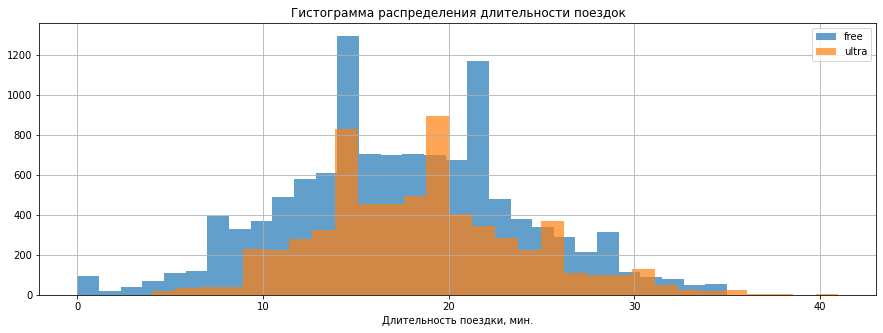

Средняя длительность поездки для пользователей без подписки 17 мин, а для пользователей с подпиской 19 мин


In [71]:
# Гистограмма длительности поездки для пользователей с подпиской и без
plt.figure(figsize=(15, 5))
df_free['duration'].hist(bins=30, label='free', alpha=0.7)
df_ultra['duration'].hist(bins=30, label='ultra', alpha=0.7)
plt.xlabel('Длительность поездки, мин.')
plt.title('Гистограмма распределения длительности поездок')
plt.legend()
plt.show()

# Расчет и вывод на экран средней длительности поездки для пользователей с подпиской и без
mean_duration_free = round(df_free['duration'].mean())
mean_duration_ultra = round(df_ultra['duration'].mean())
print(f'Средняя длительность поездки для пользователей без подписки {mean_duration_free} мин, а для пользователей с подпиской {mean_duration_ultra} мин')

- Оба распределения **близки к нормальному**, с пиком в районе **15–22 минут**.
- Заметны **два выраженных пика** (около 16 и 21–22 минут) — вероятно, это связано с типичными сценариями использования: короткая поездка «до метро» и чуть более длинная «прогулочная».
- Оранжевое распределение (`ultra`) **сдвинуто вправо** относительно синего (`free`): у подписчиков чуть больше доля поездок средней и повышенной длительности (20–30 минут).
- У пользователей без подписки (`free`) заметнее **левый «хвост»** — поездок короче 10 минут у них больше, чем у подписчиков.
- Оба «хвоста» — и короткие, и длинные поездки — выражены слабо: подавляющая часть поездок укладывается в диапазон **10–30 минут**.

**Числовые результаты:**

- Средняя длительность поездки у пользователей **без подписки** — **17 минут**.
- Средняя длительность поездки у пользователей **с подпиской** — **19 минут**.

**Интерпретация:**

- Разница в средних составляет **2 минуты** в пользу подписчиков. Это **небольшое, но устойчивое** различие, которое согласуется с формой графиков: распределение `ultra` смещено вправо.
- Это **предварительное наблюдение**, а не доказательство: чтобы утверждать, что подписчики действительно тратят больше времени на поездки, необходимо провести **статистическую проверку гипотезы** 
- Если гипотеза подтвердится, это станет **аргументом в пользу выгодности подписки** для компании: подписчики не только платят фиксированную сумму, но и проводят в поездках больше времени, что повышает их ценность для сервиса.

## 5. Подсчет выручки

Сгруппируем данные по следующим столбцам: `user_id`, `name`, `subscription_type`, `month`.

In [72]:
df_gp = df.groupby(['user_id', 'name', 'subscription_type', 'month'], as_index=False)

Создадим новый датафрейм `df_agg`. В нём для каждой группы рассчитаем и добавим в датафрейм следующие агрегированные значения, используя метод `agg()`:

- `total_distance` — сумма значений в столбце `distance`.
- `total_duration` — сумма значений в столбце `duration`.
- `rides_count` — количество элементов в столбце `duration`.
- `subscription_type` — первое значение в группе для столбца `subscription_type`.
- `minute_price` — первое значение в группе для столбца `minute_price`.
- `start_ride_price` — первое значение в группе для столбца `start_ride_price`.
- `subscription_fee` — первое значение в группе для столбца `subscription_fee`.

In [73]:
df_agg = df_gp.agg(
    total_distance=('distance', 'sum'),
    total_duration=('duration', 'sum'),
    rides_count=('duration', 'count'),
    subscription_type=('subscription_type', 'first'),
    minute_price=('minute_price', 'first'),
    start_ride_price=('start_ride_price', 'first'),
    subscription_fee=('subscription_fee', 'first')
).reset_index(drop=True)

Создадим функцию `calculate_monthly_revenue(row)` для расчёта месячной выручки по формуле:

`monthly_revenue` = `start_ride_price` * `rides_count` + `minute_price` * `total_duration` + `subscription_fee`

В качестве входных данных функция будет принимать одну строку `row` датафрейма. 

- `start_ride_price * rides_count` — выручка от начала каждой поездки.
- `minute_price * total_duration` — выручка за время использования.
- `subscription_fee` — фиксированная выручка от подписок.

In [75]:
def calculate_monthly_revenue(row):
    monthly_revenue = row['start_ride_price'] * row['rides_count'] + row['minute_price'] * row['total_duration'] + row['subscription_fee']
    return monthly_revenue

Создадим новый столбец с месячной выручкой на пользователя `monthly_revenue`. Для этого применим функцию `calculate_monthly_revenue(row)` к каждой строке агрегированного датафрейма `df_agg`.

In [76]:
df_agg['monthly_revenue'] = df_agg.apply(calculate_monthly_revenue, axis=1)

Исследуем полученные значения выручки. Найдем пользователя с максимальной суммарной выручкой за весь период наблюдения и для него выведем на экран `user_id`, имя, месяц, количество поездок и выручку за каждый из месяцев.

In [77]:
max_user_id = df_agg.groupby('user_id')['monthly_revenue'].sum().idxmax()
display(df_agg[df_agg['user_id'] == max_user_id][['user_id', 'name', 'month', 'rides_count', 'monthly_revenue']])

,user_id,name,month,rides_count,monthly_revenue
8877,1236,Александр,1,2,228
8878,1236,Александр,2,3,614
8879,1236,Александр,3,5,762
8880,1236,Александр,4,1,202
8881,1236,Александр,5,3,574
8882,1236,Александр,6,1,282
8883,1236,Александр,7,1,290
8884,1236,Александр,8,2,452
8885,1236,Александр,9,1,122
8886,1236,Александр,10,3,430


- Данные сгруппированы по `user_id`, `name`, `subscription_type`, `month`.
- Для каждой группы рассчитаны: суммарное расстояние, суммарное время, количество поездок, а также сохранены тарифные условия подписки.
- Создана функция `calculate_monthly_revenue()`, которая считает выручку по формуле:

  **`monthly_revenue = start_ride_price × rides_count + minute_price × total_duration + subscription_fee`**

  То есть выручка складывается из платы за старт каждой поездки, оплаты за минуты и фиксированного ежемесячного платежа за подписку.
- Полученный столбец `monthly_revenue` добавлен в агрегированный датафрейм `df_agg`.

**Наблюдения:**

- Найден пользователь с **максимальной суммарной выручкой** за год — **Александр (`user_id = 1236`)**.
- Его помесячная выручка варьируется **от 122 до 762 рублей**, что соответствует **1–5 поездкам в месяц**.
- Заметно, что выручка **нелинейно зависит от количества поездок**: например, при 5 поездках (март) выручка 762 руб., а при 3 поездках (февраль, май, октябрь, ноябрь) она колеблется в диапазоне 430–614 руб. Это объясняется разной суммарной длительностью поездок в каждом месяце.

**Промежуточный итог:**

- Агрегированный датафрейм `df_agg` готов к **проверке гипотез** и сравнению выручки между подписчиками и пользователями без подписки (шаг 6).
- Полученные значения `monthly_revenue` позволяют перейти к анализу того, **действительно ли подписчики приносят больше выручки помесячно**, чем пользователи без подписки.

## 6. Проверка гипотез

Напишем вспомогательную функцию `print_stattest_results(p_value, alpha)`, которая будет интерпретировать результаты статистического теста на основе p-value и заданного уровня значимости (α-уровня). Функция должна решать, следует ли принять альтернативную гипотезу или сохранить нулевую гипотезу.

У функции два параметра:
- `p_value` (тип `float`) — значение p-value, полученное в результате выполнения статистического теста.
- `alpha` (тип `float`, необязательный, по умолчанию `alpha = 0.05`) — уровень значимости статистического теста, который используется как порог для принятия решения об отклонении нулевой гипотезы.

Если мы принимаем альтернативную гипотезу, выводится сообщение:
`'Полученное значение p_value=<Введённое значение p_value> меньше критического уровня alpha=0.05. Принимаем альтернативную гипотезу.'`

Если мы не можем опровергнуть нулевую гипотезу, выводится сообщение: `'Полученное значение p_value=<Введённое значение p_value> больше критического уровня alpha=0.05. Опровергнуть нулевую гипотезу нельзя.'`

Вызовем функцию для `p_value = 0.0001` и `p_value = 0.1`.

In [79]:
def print_stattest_results(p_value:float, alpha:float = 0.05):
    # Напишите код для функции здесь
    if p_value < alpha:
        print(f'Полученное значение p_value={p_value} меньше критического уровня alpha={alpha}. Принимаем альтернативную гипотезу.')
    else:
        print(f'Полученное значение p_value={p_value} больше критического уровня alpha={alpha}. Опровергнуть нулевую гипотезу нельзя.')
print_stattest_results(p_value=0.0001)
print_stattest_results(p_value=0.1)

Полученное значение p_value=0.0001 меньше критического уровня alpha=0.05. Принимаем альтернативную гипотезу.
Полученное значение p_value=0.1 больше критического уровня alpha=0.05. Опровергнуть нулевую гипотезу нельзя.


Важно понять, тратят ли пользователи с подпиской больше времени на поездки? Сформулируем нулевую и альтернативную гипотезы:
- Нулевая гипотеза (Н0): Среднее время поездки у пользователей с подпиской и без подписки одинаковое.
- Альтернативная гипотеза (Н1): Среднее время поездки у пользователей с подпиской больше, чем у пользователей без подписки.

Чтобы проверить эту гипотезу:
1. Используем неагрегированные данные из датафреймов `df_ultra` и `df_free`, созданные на одном из прошлых шагов.
2. Используем данные о продолжительности каждой поездки `duration` — отдельно для подписчиков и тех, у кого нет подписки.
3. Рассчитаыем значение `p_value` для выбранной гипотезы, используем функции модуля `scipy.stats` и t-тест для независимых выборок (`st.ttest_ind`).
4. В качестве результата вызовем написанную функцию `print_stattest_results(p_value, alpha)`, передав ей рассчитанное значение `p_value`.
5. В конце дополнительно рассчитаем среднюю длительность поездки для тарифов `ultra` и `free`.

- **t-тест для независимых выборок (`st.ttest_ind`)** подходит, потому что мы сравниваем **средние двух независимых групп** — поездки подписчиков (`ultra`) и поездки пользователей без подписки (`free`). Один и тот же пользователь не может одновременно относиться к обеим группам, поэтому выборки независимы.
- **Параметр `alternative='greater'`** задаёт **одностороннюю** проверку. Это соответствует нашей альтернативной гипотезе: мы проверяем не просто «различаются ли средние», а именно «среднее у `ultra` **больше**, чем у `free`». Односторонний тест в этом случае более мощный и корректный.
- **Используются неагрегированные данные** `df_ultra` и `df_free` (по одной строке на поездку), а не агрегированные по пользователям — это даёт больше наблюдений и точнее оценивает распределение длительности.
- **Уровень значимости α = 0.05** — стандартный порог: если p-value < 0.05, различие считается статистически значимым.

In [80]:
ultra_duration = df_ultra['duration']
free_duration = df_free['duration']

results = st.ttest_ind (ultra_duration, free_duration, alternative='greater') 
p_value = results.pvalue
print_stattest_results(p_value)
ultra_mean_duration = round(ultra_duration.mean(), 2)
free_mean_duration = round(free_duration.mean(), 2)


print(f'Средняя длительность поездки тарифа Ultra {ultra_mean_duration}')
print(f'Средняя длительность поездки тарифа Free {free_mean_duration}')

Полученное значение p_value=3.1600689435611813e-35 меньше критического уровня alpha=0.05. Принимаем альтернативную гипотезу.
Средняя длительность поездки тарифа Ultra 18.55
Средняя длительность поездки тарифа Free 17.39


- Полученное **p-value ≈ 3.16 × 10⁻³⁵** — чрезвычайно малое значение, **намного меньше** критического уровня 0.05.
- По правилу, заложенному в `print_stattest_results()`, **нулевая гипотеза отклоняется**, принимается **альтернативная**: среднее время поездки у подписчиков **действительно больше**, чем у пользователей без подписки.
- Средние значения подтверждают это:
  - средняя длительность поездки на тарифе **Ultra** ≈ **18.55 минут**;
  - средняя длительность поездки на тарифе **Free** ≈ **17.39 минут**.
- Разница — около **1.16 минуты** в пользу подписчиков. Сама по себе она небольшая, но **статистически высокозначимая** благодаря большому объёму выборки (~18 000 поездок).

**Вывод:** гипотеза подтвердилась — подписчики в среднем ездят дольше. Это дополнительный аргумент в пользу подписки: такие пользователи не только платят фиксированную сумму, но и проводят в поездках больше времени, что усиливает их ценность для сервиса.

---

Проанализируем ещё одну важную продуктовую гипотезу. Расстояние одной поездки в 3130 метров — оптимальное с точки зрения износа самоката. Можно ли сказать, что расстояние, которое проезжают пользователи с подпиской за одну поездку, меньше 3130 метров?

Сформулируем нулевую и альтернативную гипотезы:

- Нулевая гипотеза (Н0): Средняя дистанция поездки у пользователей с подпиской равна 3130 м.

- Альтернативная гипотеза (Н1): Средняя дистанция поездки у пользователей с подпиской больше 3130 м.

Чтобы проверить эту гипотезу:

1. Используем неагрегированные данные о каждой поездке пользователей с подпиской из датафрейма `df_ultra`.

2. Используем данные о дистанции каждой поездки `distance`.

3. Рассчитаем значение `p_value` для выбранной гипотезы, используя функции модуля `scipy.stats` и одновыборочный t-тест (st.ttest_1samp). 

4. В качестве результата вызовем написанную функцию `print_stattest_results(p_value, alpha)`, передав ей рассчитанное значение `p_value`.

- Здесь мы сравниваем **среднее одной выборки** (`ultra_distance`) с **известным фиксированным значением** (3130 м), а не две группы между собой. Для такой задачи используется **одновыборочный t-тест (`st.ttest_1samp`)**.
- **Параметр `alternative='greater'`** задаёт одностороннюю проверку — мы проверяем именно гипотезу «среднее **больше** 3130», а не «отличается от 3130». Это соответствует формулировке Н₁.
- Используются **неагрегированные данные** `df_ultra` — по одной строке на каждую поездку подписчика. Это даёт максимально точную оценку среднего и стандартного отклонения.
- **α = 0.05** — стандартный порог значимости.

In [82]:
null_hypothesis = 3130
ultra_distance = df_ultra['distance']

results = st.ttest_1samp(ultra_distance, null_hypothesis, alternative='greater')
p_value = results.pvalue
print_stattest_results(p_value)

Полученное значение p_value=0.9195368847849785 больше критического уровня alpha=0.05. Опровергнуть нулевую гипотезу нельзя.


- Полученное **p-value ≈ 0.92** — это **очень большое значение**, значительно превышающее порог 0.05.
- По правилу в `print_stattest_results()` **нулевую гипотезу опровергнуть нельзя**: у нас нет статистических оснований утверждать, что средняя дистанция поездки подписчиков превышает 3130 метров.
- Иными словами, наблюдаемое среднее расстояние **статистически не отличается** от порогового значения 3130 м в сторону превышения.

**Вывод:** опасения по поводу повышенного износа самокатов из-за подписчиков **не подтверждаются**. Средняя дистанция их поездок находится на уровне оптимальных 3130 метров и не превышает его. Это хорошая новость для бизнеса: подписка не ведёт к ускоренному износу парка самокатов.

---

Проверим гипотезу о том, что выручка от пользователей с подпиской выше, чем выручка от пользователей без подписки.

Сформулируем нулевую и альтернативную гипотезы:

- Нулевая гипотеза (Н0): Средняя месячная выручка у пользователей с подпиской и без подписки одинаковая.
- Альтернативная гипотеза (Н1): Средняя месячная выручка у пользователей с подпиской выше, чем у пользователей без подписки.

Чтобы проверить эту гипотезу:
1. Используем агрегированные данные из датафрейма `df_agg`, подготовленного на шаге 5.
2. Используем исходные данные о месячной выручке от каждого пользователя — `monthly_revenue`.
3. Рассчитаем значение `p_value` для выбранной гипотезы, используя функции модуля `scipy.stats` и t-тест для независимых выборок (`st.ttest_ind`).
4. В качестве результата вызовем написанную функцию `print_stattest_results(p_value, alpha)`, передав ей рассчитанное значение `p_value`.
5. Дополнительно рассчитаем среднюю выручку для тарифов `ultra` и `free`.

- Сравниваем **средние двух независимых групп** — месячная выручка подписчиков (`ultra`) и пользователей без подписки (`free`). Один и тот же пользователь не может одновременно входить в обе группы, поэтому выборки независимы.
- Используется **t-тест для независимых выборок (`st.ttest_ind`)** — стандартный инструмент для сравнения средних двух независимых совокупностей.
- **Параметр `alternative='greater'`** задаёт **одностороннюю** проверку: нас интересует не просто наличие различий, а именно то, что выручка `ultra` **больше** выручки `free`. Это напрямую соответствует продуктовой гипотезе бизнеса.
- Используются **агрегированные данные** из `df_agg` (одна строка = один пользователь за один месяц) со столбцом `monthly_revenue`, рассчитанным на шаге 5. Это корректно, потому что гипотеза касается именно **выручки на пользователя в месяц**, а не выручки отдельной поездки.
- **α = 0.05** — стандартный порог значимости.

In [84]:
revenue_ultra = df_agg[df_agg['subscription_type'] == 'ultra']['monthly_revenue']
revenue_free = df_agg[df_agg['subscription_type'] == 'free']['monthly_revenue']

results = st.ttest_ind(revenue_ultra, revenue_free, alternative='greater')
p_value = results.pvalue
print_stattest_results(p_value)

mean_revenue_ultra = round(revenue_ultra.mean())
mean_revenue_free = round(revenue_free.mean())

print(f'Средняя выручка подписчиков Ultra {mean_revenue_ultra} руб')
print(f'Средняя выручка подписчиков Free {mean_revenue_free} руб')

Полученное значение p_value=1.7274069878387966e-37 меньше критического уровня alpha=0.05. Принимаем альтернативную гипотезу.
Средняя выручка подписчиков Ultra 359 руб
Средняя выручка подписчиков Free 322 руб


- Полученное **p-value ≈ 1.73 × 10⁻³⁷** — экстремально малое значение, **намного меньше** 0.05.
- **Нулевая гипотеза отклоняется**, принимается **альтернативная**: средняя месячная выручка подписчиков **статистически значимо выше**, чем у пользователей без подписки.
- Средние значения подтверждают вывод:
  - средняя месячная выручка подписчика **Ultra** — около **359 руб.**;
  - средняя месячная выручка пользователя **Free** — около **322 руб.**
- Разница — примерно **37 рублей в месяц** (~11.5%) в пользу подписчиков. Разрыв на первый взгляд небольшой, но **чрезвычайно устойчивый** статистически — при таком p-value вероятность случайно получить такое различие практически нулевая.

**Вывод:** гипотеза подтвердилась — подписчики приносят компании **больше выручки в месяц**, чем пользователи без подписки. Это ключевой аргумент в пользу стратегии продвижения подписки: даже с учётом фиксированной месячной платы `ultra` оказывается выгоднее для сервиса, чем тариф `free`. Значит, **акции по привлечению новых подписчиков экономически оправданы**.

##  7. Распределения

В компании возникла идея предлагать дополнительную скидку подписчикам, совершающим длительные поездки продолжительностью более 30 минут. Оценим долю таких поездок.

В одном из предыдущих заданий мы уже построили гистограмму распределения длительности поездок для выборки. Однако эти данные охватывают лишь часть пользователей всех самокатов, а нас интересуют возможные значения для всей генеральной совокупности. Учитывая, что у нас нет доступа ко всем данным о поездках, смоделируем длительность поездки с помощью нормального распределения, используя в качестве параметров выборочное среднее и стандартное отклонение из доступных данных о поездках.

**Расчёт выборочного среднего и стандартного отклонения**

1. Рассчитаем среднюю длительность поездки и сохраним в переменную `mu`.
2. Вычислим стандартное отклонение длительности `duration` и сохраним в переменную `sigma`. 
3. Зададим значение переменной `target_time`, равное `30`. Эта переменная будет использоваться для последующего вычисления вероятности.

In [85]:
# Вычисляем среднее значение
mu = df_ultra['duration'].mean()

# Вычисляем стандартное отклонение
sigma = df_ultra['duration'].std()

# Задаём целевое время
target_time = 30

# Делаем вывод
print(f'Средняя длительность поездки {round(mu, 1)}, стандартное отклонение {round(sigma, 1)}.')

Средняя длительность поездки 18.5, стандартное отклонение 5.6.


**Вычисление значения функции распределения в точке (CDF)**
Если вычислить значение функции распределения в точке, это позволит узнать вероятность того, что случайная величина примет значение меньше заданного либо равное ему. Если мы хотим ответить на вопрос о вероятности поездки более 30 минут, потребуется использовать CDF.

Используем функцию `norm()` из библиотеки `SciPy` для создания нормального распределения с параметрами `mu` и `sigma`.

Применим метод `cdf()` к целевому времени `target_time` для получения вероятности того, что случайная величина будет меньше этого значения или равна ему. Полученное значение сохраним в переменную `prob`.

In [87]:
# Вычисляем вероятность того, что случайная величина будет меньше указанного значения или равна ему

duration_norm_dist  = st.norm(mu, sigma)
prob = round(1 - duration_norm_dist.cdf(target_time), 3) # Используем CDF для нахождения накопленной вероятности

print(f'Вероятность поездки более 30 минут {prob}')

Вероятность поездки более 30 минут 0.02


**Вероятность для интервала (CDF)**
Коллеги посчитали, что процент пользователей, для которых будет показана скидка, недостаточно большой и вряд ли поможет в увеличении лояльности клиентов. Проверим, какой процент пользователей совершает поездки в интервале от 20 до 30 минут. Возможно, именно для них стоит провести промоакцию?

Для этого:

1. Создадим переменные `low` и `high`, указывающие на начало и конец интересующего временного интервала. В этом случае они равны 20 и 30 минут.
2. Используем кумулятивную функцию распределения (CDF) для объекта `duration_norm_dist`, чтобы вычислить вероятность достижения верхней границы (`high`) и нижней границы (`low`).
3. Вычислим вероятность попадания в интервал и сохраним в переменную `prob_interval`.

In [88]:
# Определяем границы интервала
low = 20
high = 30

# Вычисляем вероятность попадания в интервал
prob_interval = round(duration_norm_dist.cdf(high) - duration_norm_dist.cdf(low), 3)

# Выводим результат
print(f'Вероятность того, что пользователь совершит поездку длительностью от {low} до {high} минут: {prob_interval}')

Вероятность того, что пользователь совершит поездку длительностью от 20 до 30 минут: 0.377


**Определение критической дистанции поездок (PPF)**
Длительные поездки могут негативно сказываться на сроке службы самоката. В связи с этим принято решение установить критическую дистанцию, превышение которой будет сопровождаться дополнительной платой. Для этого необходимо определить расстояние, которое превышается только в 10% поездок (90-й процентиль).

Yаша задача — смоделировать распределение длительности поездок, предполагая, что оно подчиняется нормальному закону, и рассчитать критическую дистанцию, ниже которой находится 90% всех поездок.

Для этого:
1. Рассчитаем среднюю дистанцию поездки для всех пользователей из датафрейма `df` (с подпиской и без) и сохраним в переменную `mu`.
2. Вычислим стандартное отклонение дистанции поездки `distance` и сохраним в переменную `sigma`.
3. Зададим значение переменной `target_prob`, равное `0.90`. Эта переменная будет использоваться для последующего вычисления критической дистанции.
4. Создадим объект нормального распределения `distance_norm` с заданными значениями `mu` и `sigma`.
5. Применим к созданному нормальному распределению `distance_norm` метод `ppf()` и в качестве аргумента передадим целевую вероятность `target_prob`. Полученное значение сохраним в переменную `critical_distance`.


In [89]:
# Вычисляем среднее значение
mu = df['distance'].mean()

# Вычисляем стандартное отклонение
sigma = df['distance'].std()

# Вероятность, для которой хотим найти значение (90% случаев)
target_prob = 0.90

# Создаём объект нормального распределения
distance_norm = st.norm(mu, sigma)

# Рассчитываем критическую дистанцию для заданного процентиля поездок
critical_distance = distance_norm.ppf(target_prob)

print(f'{100 * target_prob} % поездок имеют дистанцию ниже критического значения {critical_distance:.2f} М.')

90.0 % поездок имеют дистанцию ниже критического значения 4501.94 М.




Для оценки доли длительных поездок и определения критических порогов использовано **нормальное распределение**, параметры которого рассчитаны по выборочным данным.

### 1. Доля поездок дольше 30 минут

- Параметры распределения длительности поездок подписчиков (`ultra`): **μ ≈ 18.5 мин**, **σ ≈ 5.6 мин**.
- Вероятность того, что поездка продлится **более 30 минут**, составила всего **≈ 2%**.
- Это очень малая доля — идея со скидкой для «длительных» поездок (> 30 мин) охватит лишь **каждую пятидесятую поездку**. Такой охват вряд ли заметно повлияет на лояльность клиентов.

### 2. Доля поездок в интервале 20–30 минут

- Вероятность попадания длительности поездки в диапазон **от 20 до 30 минут** составила **≈ 37.7%**.
- Это **существенно большая аудитория** — почти **каждый третий подписчик**. Промоакция, ориентированная на этот интервал, охватит гораздо больше пользователей и с большей вероятностью даст эффект в повышении лояльности.
- **Рекомендация бизнесу:** вместо порога «более 30 минут» стоит рассмотреть промо для поездок в диапазоне **20–30 минут** — это более широкая и «рабочая» аудитория.

### 3. Критическая дистанция (90-й процентиль)

- Параметры распределения дистанции по всем поездкам: **μ** и **σ**, рассчитанные по объединённому датафрейму `df`.
- **90% поездок** имеют дистанцию ниже **≈ 4501.94 м**.
- Это значит, что **критической дистанцией** для введения дополнительной платы (сверх которой оказываются только 10% самых длинных поездок) можно считать **≈ 4502 метра**.
- Такой порог защищает парк самокатов от чрезмерного износа, затрагивая лишь **меньшинство поездок**, — и при этом не создаёт неудобств для большинства пользователей.

### Итог по блоку

- Моделирование нормальным распределением показало, что **длительные поездки (> 30 мин) — редкое явление (2%)**, а **поездки 20–30 минут — массовое (≈ 38%)**.
- Порог в **4502 м** позволяет аккуратно ввести доплату за самые длинные 10% поездок, минимизируя негатив для основной массы клиентов.
- Полученные оценки можно использовать для **обоснования тарифной политики и дизайна промоакций**.

---

# Общий вывод по проекту и рекомендации для бизнеса

## Общий вывод

В ходе проекта проведен полный цикл анализа данных сервиса проката самокатов GoFast: от загрузки и предобработки данных до проверки статистических гипотез и моделирования распределений. Все ключевые задачи выполнены.

**Основные результаты:**

1. **Данные и аудитория.**
   - После удаления 31 дубликата в датафрейме пользователей осталось **1534 уникальных пользователя**.
   - Пользователи распределены по **8 городам практически равномерно** — от 11.0% (Москва) до 14.3% (Пятигорск). Явного географического перекоса нет.
   - **54% пользователей — без подписки (`free`)**, **46% — с подпиской (`ultra`)**. Более половины аудитории не подключены к платному тарифу — есть потенциал роста.
   - Возраст пользователей близок к нормальному распределению с пиком **в 25–26 лет**; ядро аудитории — **20–33 года**. Несовершеннолетние составляют лишь **5%**.    

2. **Поведение пользователей.**
   - Средняя длительность поездки — **18 минут**, стандартное отклонение — **6 минут**; основная масса поездок — **14–22 минуты**.
   - Подписчики в среднем ездят **дольше** (18.55 мин vs 17.39 мин), и это различие **статистически значимо** (p-value ≈ 3.16 × 10⁻³⁵).
   - Средняя дистанция поездки подписчиков **не превышает** оптимальные **3130 м** (p-value ≈ 0.92) — опасения по поводу повышенного износа самокатов не подтвердились.
     
3. **Выручка.**
   - Подписчики приносят в среднем **359 руб./мес**, пользователи без подписки — **322 руб./мес**.
   - Разница **статистически значима** (p-value ≈ 1.73 × 10⁻³⁷) — тариф `ultra` действительно выгоднее для компании.
     
4. **Распределения и пороги.**
   - Доля поездок **дольше 30 минут** — всего **≈ 2%**, тогда как поездки **20–30 минут** составляют **≈ 38%**.
   - **90-й процентиль** дистанции — **≈ 4502 м**; это обоснованная граница для введения доплаты за самые длинные поездки.

---

## Рекомендации для бизнеса

### 1. Продвигать подписку `ultra` как ключевой драйвер выручки
- Подписчики приносят статистически значимо **больше месячной выручки** (+37 руб./мес на пользователя) и при этом ездят **дольше**, не превышая при этом критическую дистанцию износа.
- Экономически расширение базы подписчиков **оправдано** — акции по привлечению новых `ultra`-пользователей имеют смысл.

### 2. Сделать ставку на сегмент 20–30 минут в промо
- Порог «более 30 минут» охватывает лишь **2%** поездок — слишком узко для заметного эффекта на лояльность.
- Промоакция для поездок в диапазоне **20–30 минут** затронет **≈ 38%** пользователей — это гораздо более широкая и «рабочая» аудитория.

### 3. Ввести доплату за сверхдлинные поездки
- Установить критическую дистанцию на уровне **≈ 4500 метров** (90-й процентиль).
- Это защитит парк самокатов от ускоренного износа, затронув лишь **10% самых длинных поездок** и не создавая неудобств большинству клиентов.

### 4. Учитывать возрастную специфику аудитории
- Ядро пользователей — **молодежь 20–33 лет**; маркетинговые кампании и коммуникации логично ориентировать именно на этот сегмент (соцсети, мобильные приложения, digital-каналы).
- Несовершеннолетние (5%) — небольшая, но требующая внимания группа: стоит проверить возрастную верификацию и правила безопасности.

### 5. Использовать равномерность географии как точку роста
- Поскольку пользователи распределены по городам почти равномерно, **масштабирование подписки можно вести одновременно во всех 8 городах**, без концентрации ресурсов на одном регионе.


**Итог:** данные подтверждают, что **подписка `ultra` выгодна и для компании, и для удержания пользователей**, а наиболее перспективными направлениями развития являются **продвижение подписки среди молодой аудитории 20–33 лет** и **промоакции для поездок 20–30 минут**.